# 03 · Task 1: loan-amount regression (limit setting)
**ProSit 2 · ICS553** · Predict the amount to approve, for limit-setting and provisioning.

* **Target:** `log1p(Total_Amount)` (amounts are extremely right-skewed; see 01).
* **Features:** the *shared* set (base, calendar, history; macro is joined but not a model input, see 01). `Total_Amount_to_Repay`, funding amounts and every fee/term
  column are **excluded** because they are deterministic functions of the target (feature audit in 01).
* **Validation:** the same temporal dev/test split and customer-grouped folds as Task 2. Ridge/Lasso penalties are chosen on
  fold seed A; reported scores use the independent seed B.
* **Models:** mean baseline, OLS, Ridge, Lasso, Random Forest, LightGBM, SVR (subsample).

### Running in Google Colab
Run the next cell first (it does nothing when you run locally). It mounts Google Drive, clones this repo into the Colab VM,
installs the libraries Colab lacks, reads the data from `DRIVE_DIR/data` and writes all outputs to `DRIVE_DIR/outputs`.
Outputs must live on Drive because **each Colab notebook runs on its own VM**: notebook 04 needs the files that 02 and 03
save, and checkpoints on Drive let an interrupted run resume. Put `Train.csv`, `Test.csv`, `economic_indicators.csv` and
`micro_gha.csv` in `DRIVE_DIR/data` once; every teammate uses the same layout.

In [1]:
# ---- Google Colab setup (skipped automatically when running locally) ----
import os, sys, subprocess
from pathlib import Path
if 'google.colab' in sys.modules:
    REPO_URL = 'https://github.com/1realMicheal/MLE-PROSIT-2.git'
    BRANCH = 'main'                                   # change if the team works on another branch
    DRIVE_DIR = '/content/drive/MyDrive/MLE Prosit 2'  # your Drive folder; data in DRIVE_DIR/data
    from google.colab import drive
    drive.mount('/content/drive')
    repo = Path('/content/MLE-PROSIT-2')
    if not (repo / 'src' / 'prosit2').exists():
        subprocess.run(['git', 'clone', '--depth', '1', '-b', BRANCH, REPO_URL, str(repo)], check=True)
    else:
        subprocess.run(['git', '-C', str(repo), 'pull', '--ff-only'], check=False)
    os.chdir(repo)
    # Colab already has numpy/pandas/scipy/scikit-learn/matplotlib; install only what is missing (no version pins,
    # so no runtime restart is needed). Tested versions are listed in requirements.txt.
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'imbalanced-learn', 'lightgbm', 'xgboost', 'shap', 'fairlearn'], check=True)
    data_dir = Path(DRIVE_DIR) / 'data'
    os.environ['PROSIT2_DATA_DIR'] = str(data_dir if (data_dir / 'Train.csv').exists() else repo / 'data')
    os.environ['PROSIT2_OUT_DIR'] = str(Path(DRIVE_DIR) / 'outputs')   # FAST mode writes to outputs_fast automatically
    assert (Path(os.environ['PROSIT2_DATA_DIR']) / 'Train.csv').exists(), f'Put Train.csv etc. in {data_dir}'
    print('Colab ready | data:', os.environ['PROSIT2_DATA_DIR'], '| outputs:', os.environ['PROSIT2_OUT_DIR'])
else:
    print('Not running in Colab: nothing to do.')

Not running in Colab: nothing to do.


In [2]:
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'prosit2').exists())
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from prosit2.config import CFG, apply_fast_mode, output_dirs, write_environment, savefig, seed_everything, money, F

# CFG.update(FAST=True)        # <- uncomment for a quick smoke test (or set env PROSIT2_FAST=1)
apply_fast_mode(CFG)
SEED = CFG['SEED']; seed_everything(SEED)
DIRS = output_dirs(CFG)
FX, CUR = money(CFG)           # report amounts in GHS only once CFG['FX_TO_GHS'] is set
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
print(f'Repo root: {ROOT}\nOutputs:   {CFG["OUT_DIR"]}\nFAST mode: {CFG["FAST"]} | currency for reporting: {CUR}')

Repo root: <repo>
Outputs:   <repo>\outputs
FAST mode: False | currency for reporting: KES


In [3]:
import joblib
from scipy import stats
from prosit2.data import prepare_dataset, make_folds
from prosit2.models import reg_est
from prosit2.evaluation import reg_metrics
write_environment(DIRS, CFG, 'environment_03.json')
ds = prepare_dataset(CFG)
dev, test = ds.dev, ds.test
REG_FEATS = ds.shared
FOLDS_A = make_folds(dev, ds.y_dev, ds.g_dev, SEED + 1, CFG['N_FOLDS'])
FOLDS_B = make_folds(dev, ds.y_dev, ds.g_dev, SEED, CFG['N_FOLDS'])
ylog_dev, ylog_te = np.log1p(dev['Total_Amount'].values), np.log1p(test['Total_Amount'].values)
leak = [c for c in REG_FEATS if c in ds.groups['terms'] or c in ('Total_Amount', 'Total_Amount_to_Repay', 'Amount_Funded_By_Lender')]
assert not leak, f'Task 1 features must not contain loan-term columns: {leak}'
print(f'{len(REG_FEATS)} Task 1 features:', REG_FEATS)

Train (68654, 16) -> cleaned 68,654 loans (default rate 1.832%)
Test starts 2022-11-02 | dev 52,331 (defaults 674, 1.29%) | test 13,775 (defaults 533, 3.87%) | purged 2,548
Feature groups: {'base': 4, 'calendar': 7, 'terms': 7, 'history': 8, 'macro': 7} | model features: Task 2 = 26, Task 1 = 19 (macro as model input: False)


19 Task 1 features: ['duration', 'loan_type', 'lender_id', 'New_versus_Repeat', 'disb_month', 'disb_quarter', 'disb_dow', 'disb_dom', 'disb_month_end', 'due_dow', 'due_weekend', 'log_n_prior_loans', 'no_prior_loans', 'log_days_since_last_loan', 'log_prior_mean_amount', 'log_last_amount', 'log_n_resolved_prior', 'log_n_prior_defaults', 'prior_default_rate']


## 1. Derivation: linear regression by maximum likelihood → normal equations (LO3)
Let $y\in\mathbb R^n$ be the log amounts and $X\in\mathbb R^{n\times (p+1)}$ the design matrix (intercept column, standardised
numeric features, one-hot categories). Assume
$$y = X\beta + \varepsilon,\qquad \varepsilon \sim \mathcal N(0, \sigma^2 I_n).$$

**Likelihood.** Each $y_i \sim \mathcal N(x_i^\top\beta, \sigma^2)$ independently, so
$$\ell(\beta,\sigma^2) = -\frac n2\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\,\lVert y - X\beta\rVert^2 .$$
For any fixed $\sigma^2$, maximising $\ell$ over $\beta$ is the same as **minimising the residual sum of squares**
$\mathrm{RSS}(\beta) = (y - X\beta)^\top(y - X\beta)$: under Gaussian errors, MLE = least squares.

**Normal equations.** $\nabla_\beta \mathrm{RSS} = -2X^\top(y - X\beta) = 0 \;\Rightarrow\; X^\top X\,\hat\beta = X^\top y$, so if
$X^\top X$ is invertible (full column rank)
$$\hat\beta = (X^\top X)^{-1}X^\top y .$$
The Hessian $2X^\top X$ is positive semi-definite, so this is a global minimum. Differentiating $\ell$ in $\sigma^2$ gives
$\hat\sigma^2_{\text{MLE}} = \mathrm{RSS}(\hat\beta)/n$ (biased; the unbiased estimator divides by $n-p-1$).

**Geometry.** $\hat y = Hy$ with the hat matrix $H = X(X^\top X)^{-1}X^\top$, an orthogonal projection onto the column space of $X$.
The normal equations say $X^\top \hat e = 0$: residuals are orthogonal to every column, so with an intercept they sum to zero.
That is what the residual-vs-fitted plot below checks (no remaining structure).

**Why we also fit Ridge and Lasso.** With a full one-hot encoding plus an intercept, the dummy columns sum to the intercept
column, so $X^\top X$ is singular (the *dummy-variable trap*); amounts are also highly collinear. Ridge adds an L2 penalty:
$$\hat\beta_{\text{ridge}} = \arg\min_\beta \lVert y - X\beta\rVert^2 + \alpha\lVert\beta\rVert^2 = (X^\top X + \alpha I)^{-1}X^\top y,$$
which is invertible for any $\alpha > 0$ and is the MAP estimate under the prior $\beta \sim \mathcal N(0, \tfrac{\sigma^2}{\alpha}I)$.
Lasso uses $\alpha\lVert\beta\rVert_1$ (a Laplace prior); it has no closed form and is solved by coordinate descent, whose update is
the soft-threshold $\beta_j \leftarrow S(z_j, \alpha) = \mathrm{sign}(z_j)\max(|z_j| - \alpha, 0)$ (scaled by $1/\lVert x_j\rVert^2$), which sets some coefficients exactly to zero.
(scikit-learn does not penalise the intercept.)

**Back-transforming the log model.** We predict $\hat\mu = \widehat{\log(1+A)}$. $e^{\hat\mu}-1$ estimates the **median** amount,
not the mean: under normal log-errors $\mathbb E[A] \approx e^{\hat\mu + \sigma^2/2} - 1$. Errors on the original scale
are dominated by the largest loans, which is why RMSE is reported on both scales.

In [4]:
def reg_cv(name, folds, alpha=None):
    oof = np.zeros(len(ylog_dev))
    for tr_i, va_i in folds:
        oof[va_i] = reg_est(name, REG_FEATS, alpha, CFG).fit(dev.iloc[tr_i], ylog_dev[tr_i]).predict(dev.iloc[va_i])
    return oof

ALPHAS = {'ridge': [0.1, 1, 10, 100], 'lasso': [1e-4, 1e-3, 1e-2]}
best_alpha = {}
for m, grid in ALPHAS.items():
    sc = {a: reg_metrics(ylog_dev, reg_cv(m, FOLDS_A, a))['rmse_log'] for a in grid}
    best_alpha[m] = min(sc, key=sc.get); print(f'{m}: RMSE(log) by alpha on seed-A folds {sc} -> {best_alpha[m]}')
REG_RES, REG_OOF = [], {}
for name in ['mean', 'ols', 'ridge', 'lasso', 'rf', 'lgbm', 'svr']:
    mp = DIRS['ckpt_reg'] / f'{name}.joblib'
    REG_OOF[name] = reg_cv(name, FOLDS_B, best_alpha.get(name))
    joblib.dump(reg_est(name, REG_FEATS, best_alpha.get(name), CFG).fit(dev, ylog_dev), mp)
    REG_RES.append({'model': name, **reg_metrics(ylog_dev, REG_OOF[name])}); print('  done', name)
reg_tab = pd.DataFrame(REG_RES).set_index('model').sort_values('rmse_log')
display(reg_tab.round(4)); reg_tab.to_csv(DIRS['results'] / 'regression_cv_results.csv')
print(f'Original-scale errors are in {CUR} (multiply by an FX rate to report in GHS).')

ridge: RMSE(log) by alpha on seed-A folds {0.1: 0.8671217357713162, 1: 0.8670779450651479, 10: 0.8669557658099089, 100: 0.8669587313824172} -> 10


lasso: RMSE(log) by alpha on seed-A folds {0.0001: 0.8669870281202539, 0.001: 0.8672035173240062, 0.01: 0.8694326900548193} -> 0.0001


  done mean


  done ols


  done ridge


  done lasso


  done rf


  done lgbm


  done svr


,rmse_log,mae_log,rmse_orig,mae_orig,r2_log
model,,,,,
lgbm,0.8507,0.6264,19519.5335,6079.0218,0.5263
rf,0.8559,0.6292,19559.7239,6084.1490,0.5204
lasso,0.8661,0.6447,34447.5422,6730.4833,0.5090
ridge,0.8661,0.6447,36256.0877,6765.7697,0.5090
ols,0.8662,0.6447,44828.5198,6851.7452,0.5088
svr,0.8718,0.6160,21090.1436,6046.7172,0.5024
mean,1.2362,0.9770,26099.2818,8801.4592,-0.0003


Original-scale errors are in KES (multiply by an FX rate to report in GHS).


Note: for linear models the original-scale RMSE can explode when a handful of extrapolated log-predictions are exponentiated;
that is a property of back-transforming, not a bug, and it is one reason the limit rule in the scoring service caps the
approved limit at the requested amount.

## 2. One-shot test evaluation and residual diagnostics

,rmse_log,mae_log,rmse_orig,mae_orig,r2_log
mean,1.3509,0.9728,2.471477e+05,2.218432e+04,-0.0220
ridge,0.9157,0.6319,8.167991e+14,9.700467e+12,0.5304
lgbm,0.7213,0.4853,2.380548e+05,1.549113e+04,0.7086


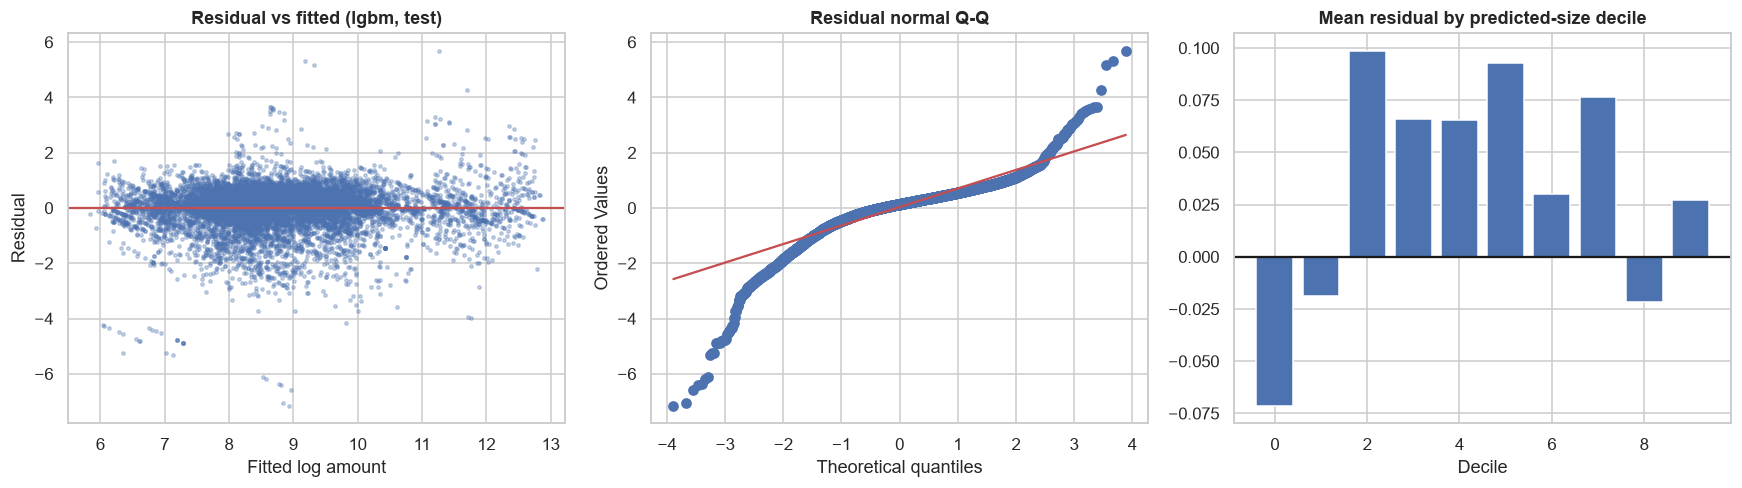

Heteroscedasticity check (corr of |residual| with fitted): 0.066
Dev OOF residual SD (log scale) = 0.851: a conservative limit can be set from a lower prediction quantile.


In [5]:
BEST_REG = reg_tab.index[0] if reg_tab.index[0] != 'mean' else reg_tab.index[1]
pipes = {n: joblib.load(DIRS['ckpt_reg'] / f'{n}.joblib') for n in dict.fromkeys(['mean', 'ridge', BEST_REG])}
pred_te = {n: p.predict(test) for n, p in pipes.items()}
reg_test = pd.DataFrame({n: reg_metrics(ylog_te, pr) for n, pr in pred_te.items()}).T
display(reg_test.round(4)); reg_test.to_csv(DIRS['results'] / 'regression_test_results.csv')
res = ylog_te - pred_te[BEST_REG]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].scatter(pred_te[BEST_REG], res, s=5, alpha=.3); ax[0].axhline(0, color='r'); ax[0].set_xlabel('Fitted log amount'); ax[0].set_ylabel('Residual'); ax[0].set_title(f'Residual vs fitted ({BEST_REG}, test)')
stats.probplot(res, plot=ax[1]); ax[1].set_title('Residual normal Q-Q')
bands = pd.qcut(pred_te[BEST_REG], 10, duplicates='drop'); rb = pd.Series(res).groupby(bands).mean()
ax[2].bar(range(len(rb)), rb.values); ax[2].axhline(0, color='k'); ax[2].set_title('Mean residual by predicted-size decile'); ax[2].set_xlabel('Decile')
plt.tight_layout(); savefig(fig, DIRS, 'plots_eval', 'regression_diagnostics')
resid_sd = float(np.std(ylog_dev - REG_OOF[BEST_REG]))
print('Heteroscedasticity check (corr of |residual| with fitted): %.3f' % np.corrcoef(np.abs(res), pred_te[BEST_REG])[0, 1])
print(f'Dev OOF residual SD (log scale) = {resid_sd:.3f}: a conservative limit can be set from a lower prediction quantile.')

In [6]:
# Linear-model coefficients (interpretability): which shared features move the predicted amount?
rp = pipes['ridge']; co = pd.DataFrame({'feature': rp.named_steps['prep'].get_feature_names_out(), 'coef': rp.named_steps['reg'].coef_})
co['multiplier on amount per SD'] = np.exp(co.coef); co = co.reindex(co.coef.abs().sort_values(ascending=False).index)
display(co.head(12).round(4)); co.to_csv(DIRS['results'] / 'ridge_coefficients.csv', index=False)
joblib.dump(dict(BEST_REG=BEST_REG, REG_FEATS=REG_FEATS, resid_sd=resid_sd, best_alpha=best_alpha, reg_tab=reg_tab, reg_test=reg_test,
                 model_path=str(DIRS['ckpt_reg'] / f'{BEST_REG}.joblib')), DIRS['artifacts'] / 'regression.joblib')
print('Saved', DIRS['artifacts'] / 'regression.joblib')

,feature,coef,multiplier on amount per SD
11,num__log_prior_mean_amount,0.7631,2.1450
19,cat__loan_type_Type_5,0.3749,1.4549
17,cat__loan_type_Type_10,-0.3498,0.7048
21,cat__loan_type_infrequent_sklearn,-0.3479,0.7062
22,cat__lender_id_245684,0.3134,1.3680
27,cat__New_versus_Repeat_Repeat Loan,0.2483,1.2819
26,cat__New_versus_Repeat_New Loan,-0.2483,0.7801
24,cat__lender_id_267278,-0.2003,0.8185
23,cat__lender_id_251804,-0.1909,0.8262
6,num__due_dow,-0.1667,0.8465


Saved <repo>\outputs\artifacts\regression.joblib


**Interpretation guide.** If RMSE(log) barely improves on the mean baseline, loan size is mostly *chosen by the product and
lender*, not predictable from the borrower, and a model-based limit adds little: say so. Systematic residual patterns by size
decile (over-predicting small loans, under-predicting large ones) would make limits **regressive** for small borrowers, which
feeds into the loan-size fairness analysis in 04.